# Default Credit Card: Exploratory and Statistical Analysis

## Part I — Exploratory Data Analysis

### 1.1 Introduction and Initial Data Inspection

This case study examines the supplied credit card client dataset.
The analysis explores customer characteristics, credit-related
measurements, repayment information, and next-month default status.

In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Read the supplied file without modifying the original data.
data_path = Path("DefaultCreditCard.csv")
df_raw = pd.read_csv(data_path)

# Use a separate copy for subsequent analysis.
df = df_raw.copy()

print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

display(df.head())

Number of observations: 1000
Number of variables: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,30,50000.0,1,1,2,26,0,0,0,0,...,17907.0,18375.0,11400.0,1500.0,1500.0,1000.0,1000.0,1600.0,0.0,0
1,64,50000.0,2,2,1,46,0,0,0,-2,...,0.0,0.0,0.0,1000.0,0.0,0.0,0.0,0.0,0.0,1
2,72,320000.0,1,2,2,29,2,2,2,2,...,58622.0,62307.0,63526.0,2500.0,2500.0,0.0,4800.0,2400.0,1600.0,1
3,113,280000.0,1,2,1,41,2,2,2,2,...,144401.0,152174.0,149415.0,6500.0,0.0,14254.0,14850.0,0.0,5000.0,0
4,133,420000.0,1,2,1,34,0,0,0,0,...,220951.0,210606.0,188108.0,9744.0,9553.0,7603.0,7830.0,7253.0,11326.0,0


In [3]:
# Inspect storage types, missing values, and distinct values.
data_check = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique(dropna=False)
})

display(data_check)

print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate IDs:", int(df["ID"].duplicated().sum()))

# Check that the outcome contains only the expected binary codes.
target = "default.payment.next.month"
assert df[target].isin([0, 1]).all(), "Unexpected default codes found."

default_summary = (
    df[target]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Default code")
    .to_frame("Number of clients")
)

default_summary["Percentage (%)"] = (
    default_summary["Number of clients"] / len(df) * 100
)

display(default_summary.round(4))

,Data type,Missing values,Unique values
ID,int64,0,1000
LIMIT_BAL,float64,0,57
SEX,int64,0,2
EDUCATION,int64,0,6
MARRIAGE,int64,0,4
AGE,int64,0,45
PAY_0,int64,0,10
PAY_2,int64,0,10
PAY_3,int64,0,9
PAY_4,int64,0,8


Total missing values: 0
Duplicate rows: 0
Duplicate IDs: 0


,Number of clients,Percentage (%)
Default code,,
0,784,78.4
1,216,21.6


### 1.2 Data Quality and Variable Types

The supplied dataset contains 1,000 observations and 25 original variables. Each observation represents one credit card client. There are no missing values detected by pandas, no fully duplicated rows, and no duplicated client IDs.

The next-month default variable contains 216 defaults and 784 non-defaults, giving a sample default rate of 21.6%.

ID is an identifier rather than a numerical measurement. LIMIT_BAL, AGE, the bill amounts, and the payment amounts are quantitative variables. SEX, EDUCATION, MARRIAGE, and the default indicator are categorical variables, although they are stored as integers. The repayment-status variables are coded categories and should not automatically be treated as continuous measurements.

The absence of missing values does not guarantee that every code has a clearly documented meaning. Category codes will be checked before they are interpreted or recoded.

The original data are retained. No observations are removed merely because their values are large or because a bill amount is negative. Such values require investigation rather than automatic deletion.

### 1.3 Numerical Descriptive Statistics

The following table summarises credit limit, age, and the bill and payment amounts recorded in BILL_AMT1 and PAY_AMT1.

The mean and median describe the centre of each distribution. The sample standard deviation and quartiles describe its spread. ID and categorical codes are excluded from this numerical summary.

In [4]:
# Select quantitative variables for the descriptive summary.
numeric_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "PAY_AMT1"
]

# describe() calculates the count, mean, sample standard deviation,
# minimum, quartiles, and maximum.
# .T puts variables in rows, making the table easier to read.
descriptive_stats = df[numeric_columns].describe().T

descriptive_stats = descriptive_stats.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

display(descriptive_stats.round(4))

,N,Mean,SD,Minimum,Q1,Median,Q3,Maximum
LIMIT_BAL,1000.0,174080.000,132714.6065,10000.0,60000.00,150000.0,250000.00,680000.0
AGE,1000.0,35.412,9.4155,21.0,28.00,34.0,41.00,66.0
BILL_AMT1,1000.0,51341.698,74935.4060,-9095.0,2902.50,20952.5,68287.75,568532.0
PAY_AMT1,1000.0,5942.817,15732.8510,0.0,861.75,2100.0,5253.00,244500.0


#### Interpretation of the Numerical Summary

The mean credit limit is 174,080, compared with a median of 150,000.The higher mean suggests that larger credit limits pull the average upward. The distribution will be examined further using visualisation.

The mean age is 35.412 years and the median is 34 years. These figures describe all clients in the sample, not only those who default. The age profile of defaulting clients will be examined separately.

For BILL_AMT1, the mean is 51,341.698 and the median is 20,952.5. For PAY_AMT1, the mean is 5,942.817 and the median is 2,100. These substantial mean–median differences suggest right-skewed distributions, which will require graphical inspection.

From a business perspective, relying only on average monetary amounts may give an incomplete picture of a typical customer. Reporting medians and quartiles alongside means helps describe both typical values and variation across clients.

These descriptive results do not establish which characteristics cause default, and large observations are not automatically errors.

### 1.4 Categorical Descriptive Statistics

The following tables report the number and percentage of clients in each category of SEX, EDUCATION, MARRIAGE, and next-month default status.

The original category codes are retained at this stage. These codes represent categories rather than numerical quantities, so their means and standard deviations are not used to describe the groups.

Percentages in each table use all 1,000 clients as the denominator. These percentages describe the composition of the sample; they are not default rates within demographic groups.

In [5]:
# Summarise categorical variables using counts and percentages.
categorical_columns = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "default.payment.next.month"
]

for column in categorical_columns:
    counts = df[column].value_counts(dropna=False).sort_index()

    summary = counts.rename_axis("Category code").to_frame(
        name="Number of clients"
    )

    summary["Percentage (%)"] = (
        summary["Number of clients"] / len(df) * 100
    )

    print(f"\nVariable: {column}")

    display(
        summary.style.format({
            "Number of clients": "{:.0f}",
            "Percentage (%)": "{:.4f}"
        })
    )


Variable: SEX


,Number of clients,Percentage (%)
Category code,,
1,397,39.7000
2,603,60.3000



Variable: EDUCATION


,Number of clients,Percentage (%)
Category code,,
1,343,34.3000
2,479,47.9000
3,162,16.2000
4,5,0.5000
5,10,1.0000
6,1,0.1000



Variable: MARRIAGE


,Number of clients,Percentage (%)
Category code,,
0,1,0.1000
1,465,46.5000
2,526,52.6000
3,8,0.8000



Variable: default.payment.next.month


,Number of clients,Percentage (%)
Category code,,
0,784,78.4000
1,216,21.6000


#### Interpretation of the Categorical Summary

For SEX, category 1 contains 397 clients (39.7%) and category 2 contains 603 clients (60.3%). The unequal group sizes mean that default counts alone would not provide a fair comparison. The analysis in Part II will therefore compare within-group default proportions.

For EDUCATION, codes 1, 2, and 3 account for 34.3%, 47.9%, and 16.2% of the sample, respectively. Codes 4, 5, and 6 together account for 1.6%. MARRIAGE includes one observation coded 0. The meanings of these codes require reference to the data documentation; they are not automatically treated as missing values or deleted.

There are 216 clients with next-month default status 1 and 784 with status 0. The overall sample default rate is therefore 21.6%. This provides a descriptive baseline for the subsequent group comparisons.

From a business perspective, the category counts help identify unequal group sizes and small categories. Comparisons involving small categories may be imprecise, so their results would need careful interpretation.

### 1.5 Exploratory analysis with visualizations

#### 1.5.1 Credit Limit by Next-Month Default Status

The following boxplots compare the distribution of credit limits between clients who do not default and those who default in the next month.

The line inside each box represents the median. The box extends from the first quartile to the third quartile. Whiskers extend to the most extreme observations within 1.5 interquartile ranges of the box. Observations beyond the whiskers are displayed individually and are retained in the analysis.

Mean credit limits are shown as diamond markers. This allows the mean and median to be compared within each group.

,N,Mean,Median,SD
Next-month default status,,,,
No default,784,185216.8367,160000.0000,134916.6676
Default,216,133657.4074,95000.0000,115995.4018


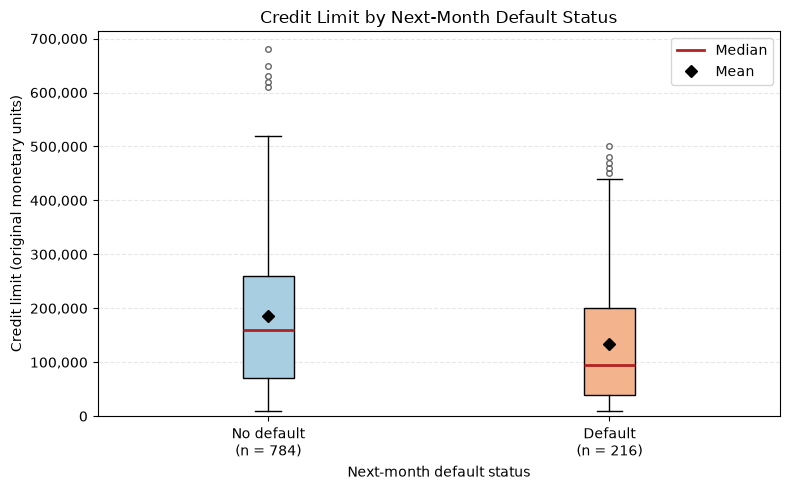

In [6]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter

target = "default.payment.next.month"

# Select credit limits for the two groups.
non_default_limits = df.loc[df[target] == 0, "LIMIT_BAL"]
default_limits = df.loc[df[target] == 1, "LIMIT_BAL"]

# Display group statistics to support the interpretation.
credit_summary = (
    df.groupby(target)["LIMIT_BAL"]
    .agg(["count", "mean", "median", "std"])
    .reindex([0, 1])
)

credit_summary.index = ["No default", "Default"]
credit_summary.index.name = "Next-month default status"
credit_summary.columns = ["N", "Mean", "Median", "SD"]

display(
    credit_summary.style.format({
        "N": "{:.0f}",
        "Mean": "{:.4f}",
        "Median": "{:.4f}",
        "SD": "{:.4f}"
    })
)

# Create boxplots without removing extreme observations.
fig, ax = plt.subplots(figsize=(8, 5))

boxplot = ax.boxplot(
    [non_default_limits, default_limits],
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 6
    },
    medianprops={
        "color": "#B22222",
        "linewidth": 2
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "none",
        "markeredgecolor": "#666666",
        "markersize": 4
    }
)

for box, color in zip(
    boxplot["boxes"], ["#A8CEE2", "#F2B38D"]
):
    box.set_facecolor(color)

ax.set_xticks([1, 2])
ax.set_xticklabels([
    f"No default\n(n = {len(non_default_limits)})",
    f"Default\n(n = {len(default_limits)})"
])

ax.set_title("Credit Limit by Next-Month Default Status")
ax.set_xlabel("Next-month default status")
ax.set_ylabel("Credit limit (original monetary units)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)

legend_items = [
    Line2D(
        [0], [0], color="#B22222",
        linewidth=2, label="Median"
    ),
    Line2D(
        [0], [0], marker="D", color="black",
        linestyle="None", markersize=6, label="Mean"
    )
]
ax.legend(handles=legend_items, loc="upper right")

ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Interpretation and Business Implication

Clients who default in the next month have a lower median credit limit (95,000) than clients who do not default (160,000). The corresponding sample means are 133,657.4074 and 185,216.8367.

In both groups, the mean exceeds the median, suggesting that higher credit limits pull the average upward. The middle 50% of credit limits ranges from 40,000 to 200,000 in the default group and from 70,000 to 260,000 in the non-default group.

The distributions overlap substantially, so credit limit alone does not clearly separate clients who default from those who do not. Observations beyond the boxplot whiskers are retained; being flagged by this rule does not establish a data error.

From a business perspective, the difference motivates further investigation of how existing credit allocation relates to default outcomes. It does not imply that increasing credit limits would reduce default or that default caused credit limits to fall.

The boxplots provide descriptive evidence. A Welch two-sample t-test in Part II will assess the difference in population means, subject to the assumptions and sampling limitations discussed in the report.

#### 1.5.2 Next-Month Default Rate by Sex

According to the UCI dataset documentation, SEX is coded as 1 for male and 2 for female.

The following chart compares the sample default rates within these two groups. Each rate is calculated by dividing the number of defaulting clients in the group by the total number of clients in that same group.

Within-group rates are used because the male and female groups have different sample sizes. The dashed line shows the overall sample default rate as a descriptive reference.

Source: [UCI Default of Credit Card Clients documentation](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).

,Number of clients,Number of defaults,Default rate (%)
Sex,,,
Male,397,92,23.1738
Female,603,124,20.5638


Male minus female default rate: 2.6100 percentage points


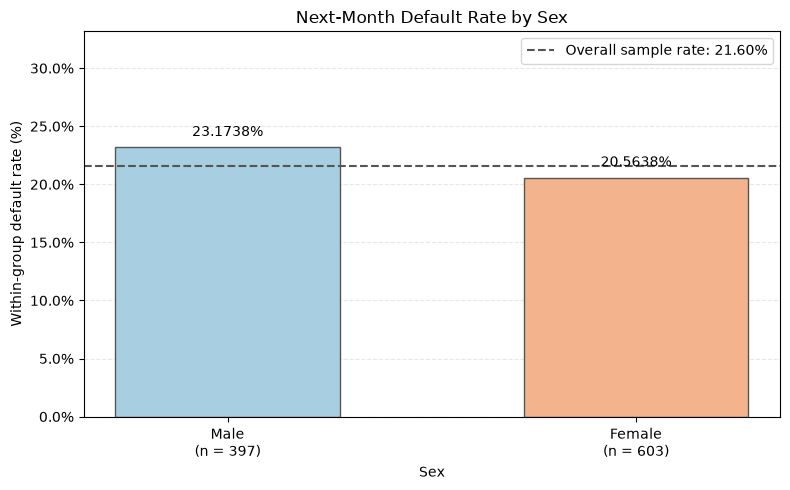

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

target = "default.payment.next.month"

# Check category codes before assigning labels.
assert df["SEX"].isin([1, 2]).all()
assert df[target].isin([0, 1]).all()

# For a binary 0/1 variable:
# count = number of clients; sum = number of defaults.
sex_summary = (
    df.groupby("SEX")[target]
    .agg(["count", "sum"])
    .reindex([1, 2])
)

sex_summary.columns = ["Number of clients", "Number of defaults"]

sex_summary["Default rate (%)"] = (
    sex_summary["Number of defaults"]
    / sex_summary["Number of clients"]
    * 100
)

sex_summary.index = ["Male", "Female"]
sex_summary.index.name = "Sex"

display(
    sex_summary.style.format({
        "Number of clients": "{:.0f}",
        "Number of defaults": "{:.0f}",
        "Default rate (%)": "{:.4f}"
    })
)

# Compute from the original data, without intermediate rounding.
overall_rate = df[target].mean() * 100
rates = sex_summary["Default rate (%)"]

difference_pp = rates.loc["Male"] - rates.loc["Female"]
print(
    f"Male minus female default rate: "
    f"{difference_pp:.4f} percentage points"
)

# Plot within-group default percentages.
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    [0, 1],
    rates.to_numpy(),
    width=0.55,
    color=["#A8CEE2", "#F2B38D"],
    edgecolor="#555555"
)

ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"Male\n(n = {sex_summary.loc['Male', 'Number of clients']})",
    f"Female\n(n = {sex_summary.loc['Female', 'Number of clients']})"
])

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 0.7,
        f"{rate:.4f}%",
        ha="center",
        va="bottom"
    )

ax.axhline(
    overall_rate,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall sample rate: {overall_rate:.2f}%"
)

ax.set_title("Next-Month Default Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Within-group default rate (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, max(rates.max(), overall_rate) + 10)
ax.legend(loc="upper right")

ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Interpretation and Business Implication

There are 92 defaults among 397 male clients and 124 defaults among 603 female clients. The corresponding sample default rates are 23.1738% and 20.5638%.

Although the female group has more defaults in absolute numbers, its within-group default rate is lower. This illustrates why counts alone can be misleading when group sizes differ.

The male sample default rate exceeds the female rate by 2.6100 percentage points. The overall sample default rate of 21.6% lies between the two group rates.

From a business perspective, this comparison provides a descriptive view of differences in customer risk profiles. However, the chart alone does not establish whether the population default proportions differ. A two-proportion z-test will be conducted in Part II.

This comparison does not adjust for other characteristics, such as age, credit limit, or repayment history. It therefore does not establish that sex causes default or that sex-based credit-limit adjustments would reduce default risk.

## Part II — Research Questions and Statistical Analysis

### 2.1 Three Research Questions Proposed By The Author：

The following questions record my initial ideas before receiving
AI-generated research questions. 

**Question 1:** Does credit card default affect a customer's ability
to borrow? Do customers who default and those who do not default
have the same borrowing amount?

My initial motivation was to understand the possible borrowing
consequences of default and the importance of timely repayment.
I initially expected to use default information and borrowing amount.

**Question 2:** Is the default rate related to sex?

My initial motivation was to investigate whether differences between
groups could inform credit-limit decisions and reduce default.
I expected to use sex and default information.

**Question 3:** What is the average age of customers who default?

My initial motivation was to understand the age profile of defaulting
customers and whether age could inform credit-card issuance decisions.
I expected to use age and default information.

### 2.2 Research Questions Proposed by AI

**AI tool:** ChatGPT

**Prompt:** Using the supplied DefaultCreditCard.csv dataset, propose three
business-relevant research questions that can be answered using
introductory statistical methods from my course, such as confidence
intervals, hypothesis tests, correlation, or simple linear regression.
Identify the variables and a suitable method for each question.
Distinguish credit limits from loan amounts and avoid causal claims.

**AI response:**

#### Question 1: What is the next-month default proportion in the population represented by this dataset?

Variable: default.payment.next.month (1 = default; 0 = no default).
Method: Calculate the sample default proportion and construct a 95% confidence interval for the population proportion. A normal-approximation interval can be used if the observed numbers of defaults and non-defaults are sufficiently large.
Business relevance: Estimating the default proportion provides a baseline measure of credit risk that can inform portfolio monitoring.
Limitation: Generalisation depends on how the supplied sample was selected and which population it represents. The estimate should not automatically be applied to all credit card customers or current market conditions.

#### Question 2: Does the mean credit limit differ between customers who default in the next month and those who do not?

Variables: LIMIT_BAL and default.payment.next.month.

Method: Use a two-sided Welch independent-samples t-test to compare the population mean credit limits of the two groups. Examine group sizes, distributions, and extreme values before interpreting the test.
$$
H_0:\mu_{\text{default}}=\mu_{\text{non-default}}
$$

$$
H_1:\mu_{\text{default}}\ne\mu_{\text{non-default}}
$$
Business relevance: This comparison can show whether existing credit limits differ between the two outcome groups and motivate further investigation of credit allocation and risk.

Limitation: LIMIT_BAL measures a credit limit, not a loan amount. A difference would indicate association; it would not establish that default caused a reduction in credit limits or that changing credit limits would change default risk. 
#### Question 3: Is there a linear association between customer age and credit limit?
Variables: AGE and LIMIT_BAL.
Method: Create a scatter plot and calculate Pearson’s correlation coefficient. A simple linear regression with credit limit as the response and age as the explanatory variable may also be used. Check whether a linear summary is reasonable and whether extreme observations strongly influence the results.
Business relevance: The analysis can describe how existing credit limits vary with age and help the bank understand the composition of its credit portfolio.
Limitation: An association does not establish that age causes differences in credit limits. Other relevant characteristics, such as income, are not included in this analysis. The findings alone would not justify age-based lending restrictions.

### 2.3 Comparison and Selection of the Final Research Questions

I compared my initial questions with the AI-generated suggestions. I selected the following three questions because they preserve my main interests and can be answered using the available variables and introductory statistical methods.

#### Final Question 1: Does the mean credit limit differ between customers who default in the next month and those who do not?

**Source:** A combination of my initial question and AI assistance.

My original question concerned borrowing amounts and the possible consequences of default. After reviewing the variables, I recognised that LIMIT_BAL measures a credit limit rather than a loan amount. The data also do not show changes in borrowing capacity after default. I therefore revised the question to compare credit limits between the two default-status groups. This revised question also matches the second AI-proposed question.

**Variables:** LIMIT_BAL and default.payment.next.month.

**Planned method:** A two-sided Welch independent-samples t-test, with a 95% confidence interval for the difference in population means. Group sizes, distributions, and extreme values will be examined.

**Business relevance:** The comparison can identify whether existing credit limits differ between the two outcome groups and motivate further investigation of credit allocation and risk. It cannot show that changing a customer's credit limit would change default risk.

#### Final Question 2: Does the next-month default proportion differ between male and female customers?

**Source:** Mainly my own initial question, refined with AI assistance.

I retained my original interest in the relationship between sex and default. AI helped clarify that I should compare default proportions, rather than numbers of defaults, because the groups may differ in size.

**Variables:** SEX and default.payment.next.month.

**Planned method:** A two-sided two-proportion z-test, after checking that the group counts support the normal approximation.

**Business relevance:** This analysis can describe differences in default proportions between the two groups and provide a starting point for further investigation of customer risk profiles. An observed difference would not establish a causal effect of sex or justify sex-based credit-limit adjustments.

#### Final Question 3: What is the estimated population mean age of customers who default in the next month?

**Source:** Mainly my own initial question, refined with AI assistance.

I retained my original question about the average age of defaulting customers. AI suggested adding a confidence interval to show the uncertainty associated with estimating a population mean from a sample.

**Variables:** AGE, restricted to customers for whom default.payment.next.month equals 1.

**Planned method:** Calculate the sample mean and construct a 95% one-sample t confidence interval for the population mean age of defaulting customers.

**Business relevance:** This analysis describes the age profile of defaulting customers. It does not identify which age group has the highest default risk, because that would require comparing defaults with the total number of customers in each age group. It therefore cannot justify age-based restrictions on credit cards.

#### Why I Did Not Select the Other AI Questions

The AI question about the overall default proportion is useful, but I will report the sample default rate in Part I and use the three final questions to examine more specific customer characteristics.

The AI question about age and credit limit is feasible, but it is less directly related to my main interest in default outcomes. I therefore prioritised my questions about differences in default
proportions and the age profile of defaulting customers.

#### Scope of Statistical Interpretation

All three analyses use the supplied sample. Population interpretations depend on the sample being sufficiently representative and observations being independent. 

For hypothesis tests, I will use a significance level of 0.05. The analyses are exploratory, and statistical significance will not be interpreted as evidence of causation or business importance.